In [1]:
import re, dataclasses, collections, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
warnings.filterwarnings("ignore")

from tcg_bot.paths import PROC
moves = pd.read_parquet(PROC / "moves.parquet")
cards = pd.read_parquet(PROC / "cards.parquet")
deck_cards = pd.read_parquet(PROC / "deck_cards.parquet")

fx = moves[moves["effect_text"].notna()].copy()          # every move that has effect text
print(len(fx), "effects with text |", fx["effect_text"].nunique(), "distinct texts")
print(fx["move_kind"].value_counts().to_dict())
print("median length:", int(fx["effect_text"].str.len().median()), "characters")

1671 effects with text | 1133 distinct texts
{'attack': 1160, 'ability': 251, 'trainer_effect': 210, 'tera': 32, 'energy_effect': 17, 'granted_attack': 1}
median length: 93 characters


whole-text templates: 957 for 1671 effects | appear once: 785 (82%)
the 50 most common templates cover 35% of effects
sentence templates: 1089 from 2351 sentences | appear once: 850
templates needed for 50% / 80% / 90% of sentences: [95, 619, 854]


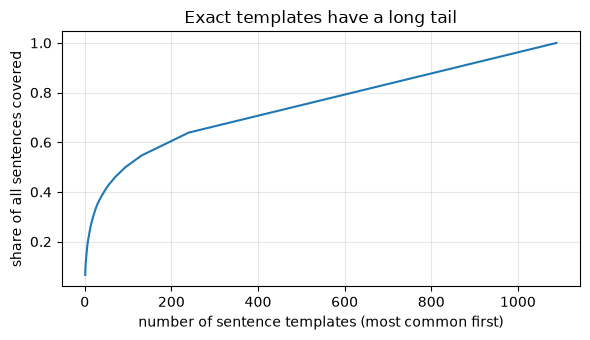

In [2]:
# --- 1. Can we tag by exact template? Mask the parts that vary, then count how often each template repeats.
pokemon_names = sorted({n for n in cards.loc[cards["family"] == "pokemon", "card_name"].dropna().unique()
                        if re.fullmatch(r"[A-Z][a-zé'’\-]{4,}", n)}, key=len, reverse=True)
NAME = re.compile(r"\b(?:" + "|".join(map(re.escape, pokemon_names)) + r")\b")

def mask(s):
    s = NAME.sub("<NAME>", s)                                      # card names
    s = re.sub(r"\{[A-Za-z ]+\}", "<E>", s)                        # energy symbols
    s = re.sub(r"\b\d+\b", "<N>", s)                               # numbers
    s = re.sub(r"\b(Asleep|Burned|Confused|Paralyzed|Poisoned)\b", "<STATUS>", s)
    return re.sub(r"\b(heads|tails)\b", "<HT>", s)

def sentences(t):
    return [x.strip() for x in re.split(r"(?<=[.!?])\s+(?=[A-Z])", re.sub(r"\s+", " ", t)) if x.strip()]

fx["masked"] = fx["effect_text"].map(mask)
whole = fx["masked"].value_counts()
print(f"whole-text templates: {len(whole)} for {len(fx)} effects | appear once: {(whole == 1).sum()} ({(whole == 1).mean():.0%})")
print(f"the 50 most common templates cover {whole.head(50).sum() / len(fx):.0%} of effects")

sent = collections.Counter(mask(s) for t in fx["effect_text"] for s in sentences(t))
counts = np.array([v for _, v in sent.most_common()]); cum = np.cumsum(counts) / counts.sum()
print(f"sentence templates: {len(sent)} from {counts.sum()} sentences | appear once: {(counts == 1).sum()}")
print("templates needed for 50% / 80% / 90% of sentences:", [int(np.searchsorted(cum, q) + 1) for q in (.5, .8, .9)])

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(1, len(cum) + 1), cum); ax.set_xlabel("number of sentence templates (most common first)")
ax.set_ylabel("share of all sentences covered"); ax.set_title("Exact templates have a long tail"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

17 patterns label 1368 of 1671 effects (82%)
labels per effect: mean 1.05, max 3


no label at all: 303 (18%) | by kind: {'attack': 148, 'ability': 101, 'trainer_effect': 46, 'energy_effect': 8}
labels with fewer than 15 examples: ['recover_discard', 'shuffle_hand']


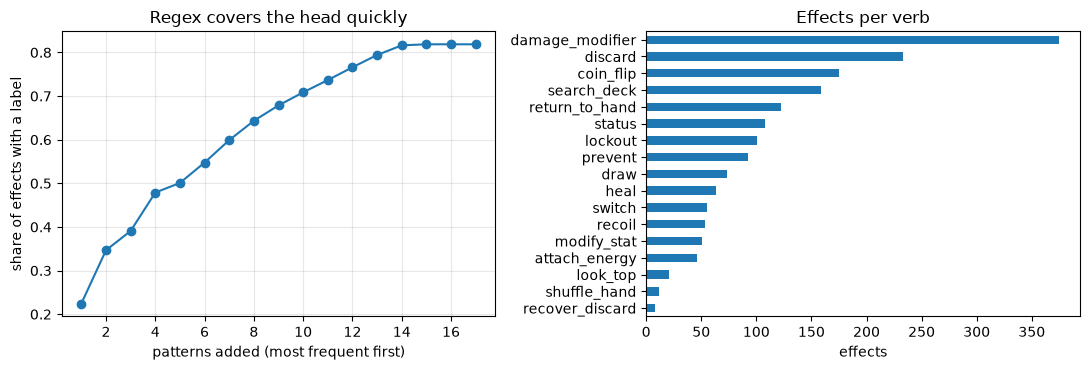

In [3]:
# --- 2. Regex first: one pattern per building-block verb. How much do they label, and how fast?
# the patterns live in one place: tcg_bot.features (switch_self / switch_opp merged back to `switch`)
from tcg_bot.features import notebook_verbs
VERBS = notebook_verbs()
labels = list(VERBS)
for k, p in VERBS.items():
    fx[k] = fx["effect_text"].str.contains(p, regex=True).astype(bool)
fx["n_labels"] = fx[labels].sum(axis=1)

print(f"{len(VERBS)} patterns label {(fx['n_labels'] > 0).sum()} of {len(fx)} effects ({(fx['n_labels'] > 0).mean():.0%})")
print(f"labels per effect: mean {fx['n_labels'].mean():.2f}, max {fx['n_labels'].max()}")
order = fx[labels].sum().sort_values(ascending=False).index
seen, curve = pd.Series(False, index=fx.index), []
for k in order:
    seen |= fx[k]; curve.append(seen.mean())
unlabelled = fx[fx["n_labels"] == 0]
print(f"no label at all: {len(unlabelled)} ({len(unlabelled) / len(fx):.0%}) | by kind: {unlabelled['move_kind'].value_counts().to_dict()}")
print("labels with fewer than 15 examples:", [k for k in labels if fx[k].sum() < 15])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(range(1, len(curve) + 1), curve, marker="o"); axes[0].set_xlabel("patterns added (most frequent first)")
axes[0].set_ylabel("share of effects with a label"); axes[0].set_title("Regex covers the head quickly"); axes[0].grid(alpha=.3)
fx[labels].sum().sort_values().plot.barh(ax=axes[1]); axes[1].set_title("Effects per verb"); axes[1].set_xlabel("effects")
plt.tight_layout(); plt.show()

In [4]:
# --- 3. How accurate are the patterns? Compare with the 54 effects written by hand (the gold set).
from tcg_bot.effects import build, MoveCards, Draw, SwitchActive, Heal, ApplyStatus, DamageSelf, Lockout, Prevent, ModifyStat, CoinFlip
from tcg_bot.effects_data import EFFECTS

def walk(x):
    if dataclasses.is_dataclass(x):
        yield x
        for f in dataclasses.fields(x):
            yield from walk(getattr(x, f.name))
    elif isinstance(x, (tuple, list)):
        for y in x:
            yield from walk(y)

def gold_labels(effect):
    g = set()
    for n in walk(effect):
        if isinstance(n, MoveCards):
            if n.look_n: g.add("look_top")
            if n.source == "deck": g.add("search_deck")
            if n.source == "discard" and n.destination == "hand": g.add("recover_discard")
            if n.destination == "attached_to_bench": g.add("attach_energy")
            if n.destination == "discard": g.add("discard")
            if n.source == "hand" and n.destination in ("deck_shuffle", "deck_bottom"): g.add("shuffle_hand")
            if n.destination == "hand": g.add("return_to_hand")
        elif isinstance(n, Draw): g.add("draw")
        elif isinstance(n, SwitchActive): g.add("switch")
        elif isinstance(n, Heal): g.add("heal")
        elif isinstance(n, ApplyStatus): g.add("status")
        elif isinstance(n, DamageSelf): g.add("recoil")
        elif isinstance(n, Lockout): g.add("lockout")
        elif isinstance(n, Prevent): g.add("prevent")
        elif isinstance(n, ModifyStat): g.add("modify_stat")
        elif isinstance(n, CoinFlip): g.add("coin_flip")
    if effect.damage is not None or effect.ignore_defender_effects or effect.ignore_weakness_resistance or effect.works_only_if:
        g.add("damage_modifier")
    return g

gold = pd.DataFrame([{"move_id": e["move_id"], **{k: k in gold_labels(build(e)) for k in labels}} for e in EFFECTS]).set_index("move_id")
g = gold.join(fx.set_index("move_id")[labels], rsuffix="_pred", how="inner")      # effects that have text
rows = []
for k in labels:
    tp = int((g[k] & g[k + "_pred"]).sum()); fp = int((~g[k] & g[k + "_pred"]).sum()); fn = int((g[k] & ~g[k + "_pred"]).sum())
    rows.append({"label": k, "tp": tp, "fp": fp, "fn": fn})
res = pd.DataFrame(rows).set_index("label"); tp, fp, fn = res.sum()
print(f"{len(g)} gold effects with text | micro precision {tp / (tp + fp):.2f}, recall {tp / (tp + fn):.2f}, F1 {2 * tp / (2 * tp + fp + fn):.2f}")
print("effects where the patterns and the hand-written data disagree:",
      [i for i in g.index if (g.loc[i, labels].values != g.loc[i, [l + "_pred" for l in labels]].values).any()])
print("\nCAUTION: these 54 effects were also used to refine the patterns, so this is an optimistic number.")
res[(res.sum(axis=1)) > 0]

45 gold effects with text | micro precision 1.00, recall 1.00, F1 1.00
effects where the patterns and the hand-written data disagree: []

CAUTION: these 54 effects were also used to refine the patterns, so this is an optimistic number.


,tp,fp,fn
label,,,
search_deck,8,0,0
look_top,1,0,0
recover_discard,1,0,0
attach_energy,1,0,0
discard,4,0,0
shuffle_hand,5,0,0
return_to_hand,12,0,0
draw,8,0,0
switch,5,0,0


unlabelled effects: nearest labelled effect has cosine median 0.55 | at least 0.5: 60% | below 0.3: 9%
one-off templates (785): nearest repeated template cosine median 0.52 | at least 0.5: 52%


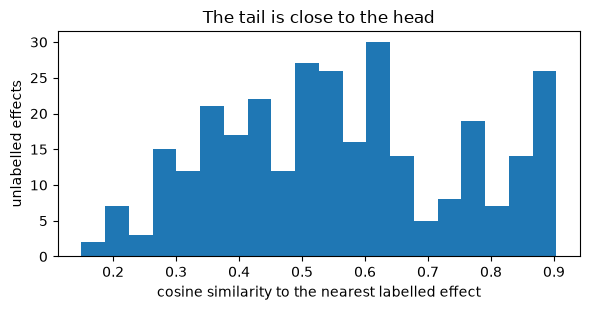

In [5]:
# --- 4. Is the unlabelled tail close to the labelled head? (what a classifier would rely on)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
X = tfidf.fit_transform(fx["masked"])
labelled = (fx["n_labels"] > 0).to_numpy(dtype=bool)
sim = cosine_similarity(X[~labelled], X[labelled]).max(axis=1)
print(f"unlabelled effects: nearest labelled effect has cosine median {np.median(sim):.2f} | at least 0.5: {(sim >= 0.5).mean():.0%} | below 0.3: {(sim < 0.3).mean():.0%}")

once = (fx["masked"].map(whole) == 1).to_numpy(dtype=bool)
sim2 = cosine_similarity(X[once], X[~once]).max(axis=1)
print(f"one-off templates ({once.sum()}): nearest repeated template cosine median {np.median(sim2):.2f} | at least 0.5: {(sim2 >= 0.5).mean():.0%}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(sim, bins=20); ax.set_xlabel("cosine similarity to the nearest labelled effect"); ax.set_ylabel("unlabelled effects")
ax.set_title("The tail is close to the head"); plt.tight_layout(); plt.show()

In [6]:
# --- 5. Feasibility of the classifier: can TF-IDF + logistic regression reproduce the labels from the text?
#        (labels here come from the patterns, so this shows the classifier can generalise from wording;
#         it does NOT show it labels the unlabelled effects correctly. That needs hand labels.)
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.metrics import f1_score

usable = [k for k in labels if fx[k].sum() >= 15]
Y = fx[usable].to_numpy(dtype=int)
clf = OneVsRestClassifier(LogisticRegression(max_iter=2000, C=10, class_weight="balanced"))
pred = cross_val_predict(clf, X, Y, cv=KFold(5, shuffle=True, random_state=0))
print(f"5-fold macro F1 over {len(usable)} labels: {f1_score(Y, pred, average='macro'):.2f}")
print({k: round(f1_score(Y[:, i], pred[:, i]), 2) for i, k in enumerate(usable)})

5-fold macro F1 over 15 labels: 0.96
{'search_deck': 1.0, 'look_top': 0.95, 'attach_energy': 0.94, 'discard': 0.97, 'return_to_hand': 0.96, 'draw': 0.93, 'switch': 0.97, 'heal': 0.98, 'status': 0.98, 'recoil': 0.98, 'lockout': 0.93, 'prevent': 0.99, 'modify_stat': 0.84, 'coin_flip': 0.99, 'damage_modifier': 0.99}


In [7]:
# --- 6. Spot-check: random effects that are NOT in your two decks, with the labels the patterns gave them.
rng = np.random.default_rng(7)
outside = fx[~fx["card_id"].isin(deck_cards["card_id"])]
for r in outside.iloc[rng.choice(len(outside), 22, replace=False)].itertuples():
    print(f"[{r.move_kind[:5]}] {r.effect_text[:150]!r}\n      -> {[k for k in labels if getattr(r, k)] or 'NO LABEL'}")

[attac] "During your next turn, this Pokémon can't attack."
      -> ['lockout']
[attac] 'Flip a coin. If tails, this attack does nothing.'
      -> ['coin_flip', 'damage_modifier']
[attac] 'Heal 30 damage from this Pokémon.'
      -> ['heal']
[attac] "Flip a coin. If heads, your opponent's Active Pokémon is now Paralyzed."
      -> ['status', 'coin_flip']
[train] 'You can use this card only if you have more Prize cards remaining than your opponent. Attach up to 2 Basic Energy cards from your discard pile to 1 of'
      -> ['attach_energy']
[attac] "If your opponent's Active Pokémon already has any damage counters on it, this attack does 200 more damage."
      -> ['damage_modifier']
[attac] 'Search your deck for up to 3 Basic Energy cards of different types, reveal them, and put them into your hand. Then, shuffle your deck.'
      -> ['search_deck', 'return_to_hand']
[train] 'Your opponent reveals their hand, and you choose an Energy card you find there and put it on the bottom of the

### 6b. How well does the classifier generalise? Three splits, each harder than the last

Section 5 used a random split, so near-copies of a wording can sit in both training and test. This section adds two
harder splits:
- **Unseen wording:** every effect with the same masked text is in the same fold.
- **Unseen family:** wordings are linked into families when their TF-IDF cosine is at least 0.7 (connected
  components), and whole families are held out.

A nearest-neighbour baseline copies the labels of the closest training effect. The labels are still the pattern
labels, so this measures how well the classifier generalises from wording, not how correct the labels are (that is
6d, the holdout).

In [8]:
from sklearn.model_selection import GroupKFold
from scipy.sparse.csgraph import connected_components

uniq = fx["masked"].unique()
Xu = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit_transform(uniq)
n_fam, fam_lab = connected_components(cosine_similarity(Xu) >= 0.7, directed=False)
fx["wording"] = fx["masked"].map({w: i for i, w in enumerate(uniq)})
fx["family_id"] = fx["masked"].map(dict(zip(uniq, fam_lab)))
print(f"{len(fx)} effects | {fx['masked'].nunique()} distinct masked wordings | {n_fam} wording families")

def run_split(splitter, groups=None):
    lr, nn = np.zeros_like(Y), np.zeros_like(Y)
    for tr, te in splitter.split(fx, Y, groups):
        vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(fx["masked"].iloc[tr])
        Xtr, Xte = vec.transform(fx["masked"].iloc[tr]), vec.transform(fx["masked"].iloc[te])
        model = OneVsRestClassifier(LogisticRegression(max_iter=2000, C=10, class_weight="balanced")).fit(Xtr, Y[tr])
        lr[te] = model.predict(Xte)
        nn[te] = Y[tr][cosine_similarity(Xte, Xtr).argmax(axis=1)]
    return lr, nn

splits = {"random": (KFold(5, shuffle=True, random_state=0), None),
          "unseen wording": (GroupKFold(5), fx["wording"]),
          "unseen family": (GroupKFold(5), fx["family_id"])}
table, per_label = {}, {}
for name, (sp, grp) in splits.items():
    lr, nn = run_split(sp, grp)
    table[name] = {"logistic regression": f1_score(Y, lr, average="macro"), "nearest neighbour": f1_score(Y, nn, average="macro")}
    per_label[name] = {k: f1_score(Y[:, i], lr[:, i]) for i, k in enumerate(usable)}
print("macro F1 over", len(usable), "labels"); print(pd.DataFrame(table).T.round(2).to_string())
fam = pd.Series(per_label["unseen family"]).round(2)
print("unseen families, logistic regression F1: modify_stat", fam["modify_stat"], "| attach_energy", fam["attach_energy"])
print("weakest four:", fam.sort_values().head(4).to_dict())

1671 effects | 957 distinct masked wordings | 556 wording families


macro F1 over 15 labels
                logistic regression  nearest neighbour
random                         0.96               0.88
unseen wording                 0.96               0.84
unseen family                  0.91               0.71
unseen families, logistic regression F1: modify_stat 0.42 | attach_energy 0.9
weakest four: {'modify_stat': 0.42, 'look_top': 0.79, 'lockout': 0.88, 'draw': 0.88}


### 6c. The gold set, with the classifier trained without it

The 45 hand-written effects that have text are removed from training. The classifier is trained on everything else and
then predicts their labels. An effect counts as *fully right* when every label in `usable` matches the hand-written
data.

In [9]:
gold_ids = set(g.index)
train = ~fx["move_id"].isin(gold_ids).to_numpy()
vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(fx["masked"][train])
model = OneVsRestClassifier(LogisticRegression(max_iter=2000, C=10, class_weight="balanced")).fit(
    vec.transform(fx["masked"][train]), Y[train])
gold_rows = fx[~train].set_index("move_id")
pred = pd.DataFrame(model.predict(vec.transform(gold_rows["masked"])), index=gold_rows.index, columns=usable).astype(bool)
truth = g.loc[pred.index, usable].astype(bool)
wrong = [m for m in pred.index if (pred.loc[m] != truth.loc[m]).any()]
print(f"{len(pred) - len(wrong)} of {len(pred)} gold effects fully right on the {len(usable)} usable labels")
for m in wrong:
    diff = {k: ("missed" if truth.at[m, k] else "extra") for k in usable if pred.at[m, k] != truth.at[m, k]}
    print("  ", m, moves.set_index("move_id").at[m, "effect_text"][:90], "->", diff)

43 of 45 gold effects fully right on the 15 usable labels
   13_0 As long as this card is attached to a Pokémon, it provides {C} Energy. When you attach thi -> {'draw': 'missed'}


   1229_0 Heal all damage from 1 of your Mega Evolution Pokémon {ex}. If you healed any damage in th -> {'return_to_hand': 'missed'}


### 6d. The holdout (run only after task H3)

`configs/tag_holdout.csv` holds 100 effects labelled **by a person, from the card text only** (Appendix A of
TASKS.md). Agents must not fill it in. These cells are tagged `skip-execution`, so they stay unrun until H3 is done.
To run them, remove the tag or run them by hand.

Expected format: one row per effect, with `move_id`, `labels` (verbs separated by `;`, or `none`) and an optional
`group` column. Scores are reported per group.

In [ ]:
from tcg_bot.paths import CONFIGS
hold = pd.read_csv(CONFIGS / "tag_holdout.csv")
assert {"move_id", "labels"} <= set(hold.columns), hold.columns.tolist()
assert hold["labels"].notna().all() and (hold["labels"].str.strip() != "").all(), "holdout not fully labelled yet (H3)"
truth_h = pd.DataFrame([{k: k in set(x.split(";")) for k in labels} for x in hold["labels"].str.replace(" ", "")],
                       index=hold["move_id"])
text_h = moves.set_index("move_id").loc[hold["move_id"], "effect_text"]
regex_h = pd.DataFrame([{k: bool(re.search(p, t)) for k, p in VERBS.items()} for t in text_h], index=hold["move_id"])
train_h = ~fx["move_id"].isin(set(hold["move_id"])).to_numpy()
vec_h = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(fx["masked"][train_h])
clf_h = OneVsRestClassifier(LogisticRegression(max_iter=2000, C=10, class_weight="balanced")).fit(
    vec_h.transform(fx["masked"][train_h]), Y[train_h])
clf_pred = pd.DataFrame(clf_h.predict(vec_h.transform(text_h.map(mask))), index=hold["move_id"], columns=usable).astype(bool)
groups = hold["group"] if "group" in hold.columns else pd.Series("all", index=hold.index)
for grp, idx in hold.groupby(groups.values).groups.items():
    ids = hold.loc[idx, "move_id"]
    print(grp, len(ids), "effects | regex macro F1", round(f1_score(truth_h.loc[ids, labels], regex_h.loc[ids, labels], average="macro", zero_division=0), 2),
          "| classifier macro F1", round(f1_score(truth_h.loc[ids, usable], clf_pred.loc[ids], average="macro", zero_division=0), 2))

Check deck tags


In [10]:
# ---- how the effect tags appear in each deck ----
import dataclasses
import pandas as pd
from pathlib import Path
from tcg_bot.decks import expand_deck
from tcg_bot.effects import (build, MoveCards, Draw, SwitchActive, Heal, ApplyStatus, DamageSelf,
                             Lockout, Prevent, ModifyStat, CoinFlip, If, ForEachPlayer)
from tcg_bot.effects_data import EFFECTS

from tcg_bot.paths import PROC
cards = pd.read_parquet(PROC / "cards.parquet")
moves = pd.read_parquet(PROC / "moves.parquet")
deck_cards = pd.read_parquet(PROC / "deck_cards.parquet")
DECKS = ["lopunny", "mega_lucario"]                       # add or remove deck names here

effects = {o.move_id: o for o in (build(e) for e in EFFECTS)}
STEPS = (MoveCards, Draw, SwitchActive, Heal, ApplyStatus, DamageSelf, Lockout, Prevent, ModifyStat, CoinFlip, If, ForEachPlayer)

def walk(x):
    if dataclasses.is_dataclass(x):
        yield x
        for f in dataclasses.fields(x):
            yield from walk(getattr(x, f.name))
    elif isinstance(x, (tuple, list)):
        for y in x:
            yield from walk(y)

def block_list(o):
    """The building blocks an effect is made of, as short labels."""
    out = []
    for n in walk(o.cost):
        if isinstance(n, MoveCards):
            out.append(f"cost:{n.source}>{n.destination}")
    for n in walk(o.steps):
        if isinstance(n, MoveCards):   out.append(f"MoveCards {n.source}>{n.destination}")
        elif isinstance(n, STEPS):     out.append(type(n).__name__)
    if o.damage is not None:                  out.append("damage formula")
    if o.works_only_if:                       out.append("works only if")
    if o.ignore_defender_effects or o.ignore_weakness_resistance: out.append("ignores defender")
    if o.requires:                            out.append("requires")
    return out

def blocks(o):
    return ", ".join(block_list(o)) or "-"

def tag_range(tags):
    first, last = tags[0], tags[-1]
    return first if first == last else f"{first} .. {last.rsplit('_', 1)[1]}"

all_rows = []
for deck in DECKS:
    inst = pd.DataFrame(expand_deck(deck_cards, cards, deck))
    rows = []
    for cid, g in inst.groupby("card_id", sort=False):
        card = cards.set_index("card_id").loc[cid]
        for m in moves[moves["card_id"] == cid].itertuples():
            o = effects.get(m.move_id)
            rows.append({
                "card tags": tag_range(g["tag"].tolist()), "x": len(g), "card": card["card_name"],
                "move": m.move_name if pd.notna(m.move_name) else m.move_kind,
                "timing": o.timing if o else "NO EFFECT",
                "usage": (o.usage.scope + (f":{o.usage.key}" if o.usage.key else "")) if o and o.usage.scope != "none" else "",
                "blocks": blocks(o) if o else "-",
                "status": o.status if o else "-",
                "_blocks": block_list(o) if o else [],
            })
    table = pd.DataFrame(rows); table.insert(0, "deck", deck); all_rows.append(table)
    print(f"\n================ {deck}: {len(inst)} cards, {len(table)} moves and effects ================")
    print(table.drop(columns=["deck", "_blocks"]).to_string(index=False, max_colwidth=62))

result = pd.concat(all_rows, ignore_index=True)

# ---- summary per deck
print("\n================ summary ================")
print(result.groupby("deck")["status"].value_counts().unstack(fill_value=0))
def kind(label):
    return "MoveCards" if label.startswith("MoveCards") else "cost" if label.startswith("cost:") else label
step_counts = (result.explode("_blocks").dropna(subset=["_blocks"])
               .assign(kind=lambda d: d["_blocks"].map(kind)).groupby(["kind", "deck"]).size().unstack(fill_value=0))
print("\nblocks used (moves and effects that use each one):")
print(step_counts.sort_values(DECKS[0], ascending=False))
print("\nmoves with no effect entry:", int((result["timing"] == "NO EFFECT").sum()))


================ lopunny: 60 cards, 34 moves and effects ================
               card tags  x                   card              move              timing             usage                                                         blocks             status
  lopunny_pokemon_1 .. 2  2                Snorunt            Chilly              attack                                                                                -                 ok
       lopunny_pokemon_3  1              Dunsparce              Gnaw              attack                                                                                -                 ok
       lopunny_pokemon_3  1              Dunsparce               Dig              attack                                                                CoinFlip, Prevent                 ok
  lopunny_pokemon_4 .. 6  3            Dudunsparce     Run Away Draw           activated       per_pokemon     Draw, If, MoveCards this_pokemon_and_attached>deck_shuffle